# EDA, distributions and outliers

Executed learning notebook for the Public Feedback Intelligence Platform.

In [1]:
from pathlib import Path
import pandas as pd
from feedback_intelligence.statistics import summarize

ROOT = Path.cwd()
frame = pd.read_csv(ROOT / "data" / "processed" / "feedback.csv")
print(frame.shape)
frame[["record_id", "category", "priority", "resolution_hours", "is_outlier"]].head()

(720, 26)


,record_id,category,priority,resolution_hours,is_outlier
0,FB-10001,billing,medium,NaN,False
1,FB-10002,account,medium,25.76,False
2,FB-10003,performance,low,55.76,False
3,FB-10004,usability,low,50.62,False
4,FB-10005,feature request,low,58.06,False


The mean uses every magnitude and therefore moves toward extreme values. The median depends on order and is usually more robust for skewed operational durations.

In [2]:
summary = summarize(frame["resolution_hours"].dropna())
{k: round(v, 3) for k, v in summary.items()}

{'count': 646.0,
 'mean': 48.626,
 'median': 44.625,
 'variance': 1008.857,
 'standard_deviation': 31.763,
 'minimum': 13.82,
 'maximum': 342.01,
 'skewness': 6.501}

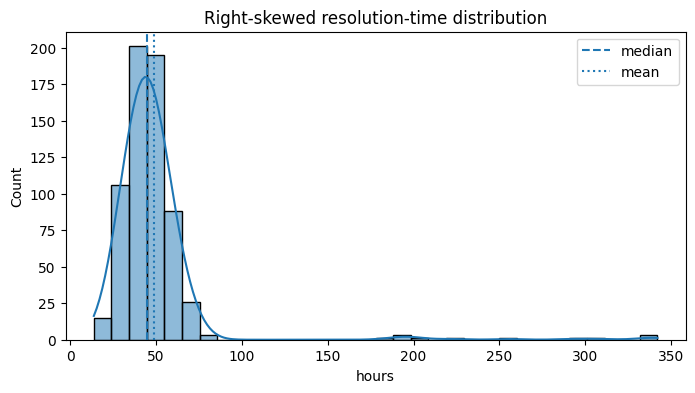

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(frame["resolution_hours"].dropna(), bins=32, kde=True, color=sns.color_palette()[0], ax=ax)
ax.axvline(frame["resolution_hours"].median(), linestyle="--", label="median")
ax.axvline(frame["resolution_hours"].mean(), linestyle=":", label="mean")
ax.set(title="Right-skewed resolution-time distribution", xlabel="hours")
ax.legend()
plt.show()

IQR flags are evidence for investigation, not automatic deletion instructions. The raw duration is preserved while a capped training-only feature limits extreme leverage.

In [4]:
frame.groupby("is_outlier")["resolution_hours"].agg(["count", "mean", "median", "max"]).round(2)

,count,mean,median,max
is_outlier,,,,
False,634,44.71,44.16,76.49
True,12,255.74,238.88,342.01
